In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [28]:
data = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"

In [29]:
df = pd.read_csv(data)

In [30]:
df.isnull().sum()


lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [31]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [32]:
categorical = ["employment_status","industry","lead_source","location"]
numerical = ["annual_income", "number_of_courses_viewed", "interaction_count", "lead_score"]
target = "converted"

In [33]:
df[categorical] = df[categorical].fillna("NA")
df[numerical] = df[numerical].fillna(0.0)

(array([1173.,    0.,    0.,  925.,    0.,    0.,  463.,    0.,    0.,
           0.,  639.,    0.,    0.,  840.,    0.,    0.,  240.,    0.,
           0.,  720.]),
 array([0. , 0.3, 0.6, 0.9, 1.2, 1.5, 1.8, 2.1, 2.4, 2.7, 3. , 3.3, 3.6,
        3.9, 4.2, 4.5, 4.8, 5.1, 5.4, 5.7, 6. ]),
 <BarContainer object of 20 artists>)

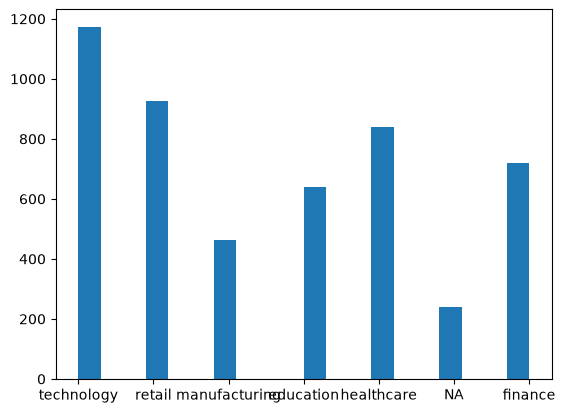

In [34]:
plt.hist(df["industry"], bins=20)

In [35]:
corr_matrix = df[numerical+[target]].corr()

In [36]:
corr_matrix

,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
annual_income,1.000000,0.161300,0.122842,0.229496,0.189652
number_of_courses_viewed,0.161300,1.000000,0.721609,0.757204,0.395038
interaction_count,0.122842,0.721609,1.000000,0.915746,0.448624
lead_score,0.229496,0.757204,0.915746,1.000000,0.483246
converted,0.189652,0.395038,0.448624,0.483246,1.000000


In [37]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42
)

In [38]:
train_y = df_train[target]
val_y = df_val[target]
test_y = df_test[target]

In [39]:
del df_train[target]
del df_val[target]
del df_test[target]

In [40]:
from sklearn.metrics import mutual_info_score

In [43]:
def mi(v1):
    return mutual_info_score(v1, train_y)

In [44]:
mitotal = df_train[categorical].apply(mi)

In [45]:
mitotal

employment_status    0.018966
industry             0.001995
lead_source          0.034346
location             0.001043
dtype: float64

In [47]:
round(mitotal, 2)

employment_status    0.02
industry             0.00
lead_source          0.03
location             0.00
dtype: float64

In [76]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [77]:
train_dict = df_train[numerical+categorical].to_dict(orient='records')

In [79]:
dv = DictVectorizer(sparse=False)

In [80]:
X_train = dv.fit_transform(train_dict)

In [81]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)

In [82]:
model.fit(X_train, train_y)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l

In [83]:
y_pred = model.predict_proba(X_train)[:,1]

In [84]:
y_pred


array([0.54986385, 0.41492578, 0.64935551, ..., 0.62831068, 0.44168571,
       0.48544926], shape=(3000,))

In [85]:
converted_decision = (y_pred>= 0.5)

In [86]:
accuracy = (train_y == converted_decision).mean()

In [87]:
round(accuracy,2)

np.float64(0.62)

In [88]:
val_dict = df_val[numerical+categorical].to_dict(orient='records')

In [89]:
X_val = dv.transform(val_dict)

In [90]:
y_pred_val = model.predict_proba(X_val)[:, 1]
converted_decision_val = (y_pred_val>=0.5)
accuracy = (val_y==converted_decision_val).mean()
round(accuracy, 2)

np.float64(0.64)

In [97]:
liste =  ['lead_source',
'number_of_courses_viewed',
'interaction_count']


In [98]:
result=[]
for i in range(3):
    features = [f for f in categorical+numerical if f != liste[i]]
    X_train = dv.fit_transform(df_train[features].to_dict(orient='records'))
    X_val = dv.transform(df_val[features].to_dict(orient='records'))

    model.fit(X_train, train_y)
    pred = model.predict_proba(X_val)[:,1]
    conv = (pred>=0.5)
    accuracy = (val_y==conv).mean()
    result.append(accuracy)
result
    

[np.float64(0.642), np.float64(0.643), np.float64(0.601)]

In [100]:
np.array(result) - 0.64

array([ 0.002,  0.003, -0.039])

In [105]:
C_list = [0.000001, 0.00001, 0.0001, 0.001]
res = []
features = categorical + numerical
for c in C_list:
    model = LogisticRegression(solver='liblinear', C=c, max_iter=1000, random_state=42)
    X_train = dv.fit_transform(df_train[features].to_dict(orient='records'))
    X_val = dv.transform(df_val[features].to_dict(orient='records'))
    
    model.fit(X_train, train_y)
    pred = model.predict_proba(X_val)[:,1]
    conv = (pred>=0.5)
    accuracy = (val_y==conv).mean()
    res.append(round(accuracy, 3))
res

[np.float64(0.598), np.float64(0.598), np.float64(0.613), np.float64(0.645)]